In [2]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import tqdm
import math
import torch


# device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
print(torch.cuda.is_available())

from torch import nn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import scipy.stats


from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from itertools import product
import cv2

False


In [ ]:
import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python312.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\dev\\src']


In [4]:
import utils

import distribution

import parameter_model
import domain

import training_context
import execution_context

import neural_net
import flow_matching

importlib.reload(distribution)
importlib.reload(utils)
importlib.reload(domain)
importlib.reload(training_context)
importlib.reload(parameter_model)
importlib.reload(neural_net)
importlib.reload(flow_matching)
importlib.reload(execution_context)


import utils

import distribution as dist

import parameter_model as param
import domain 

from training_context import TrainingContext
from execution_context import ExecutionContext

import neural_net
from flow_matching import FlowM_Model


In [13]:
D = dist.Distribution("assets/test_distributions/complex.jpg")
D.to_torch()

D.fit_gaussian()

Param_Gauss_model(mx=np.float64(0.4378356753756001), my=np.float64(0.49075871278850625), a=np.float64(0.8637677243347559), b=np.float64(8.245500537358013e-05), c=np.float64(0.1948294251088382))

##### TODOs

- Might want to have some more custom loss, which is a weighted expection, by the value difference
- Change to spherical domain so this is easily applicable to all forms of env. maps
- Idea: I have discretization for free, calculate average value of pixel v in distribution, weigh not by difference between p(x_1) and p(x_0), but instead by the difference of p(x_1) and v
  - This will cause every sample below the mean pdf value to push away from it
- Specifically for *online* path tracing now
  - Do not have time to use sample from every path for training
  - Maybe choose one sample from each workgroup according to the distribution (maybe reservoir sampling) and train a single batch with all chosen samples from the workgroups

---

In [17]:
from copy import deepcopy

create_net = lambda: neural_net.MLP(channels_in = 2, channels_t = 256, channels_out = 2, layers = [128, 128, 128])

train_context = TrainingContext(training_steps = 40000, track_score=True, track_every=100)

ex_context_unif_R2 = ExecutionContext(target_dist=D, domain=domain.R2_Domain ,input_dist=dist.Uniform_Input_Distribution)

model_unif_R2 = FlowM_Model(create_net(), ex_context_unif_R2, train_context)


scores_UR2 =model_unif_R2.train()

100%|██████████| 40000/40000 [03:18<00:00, 201.66it/s, score=0.168]


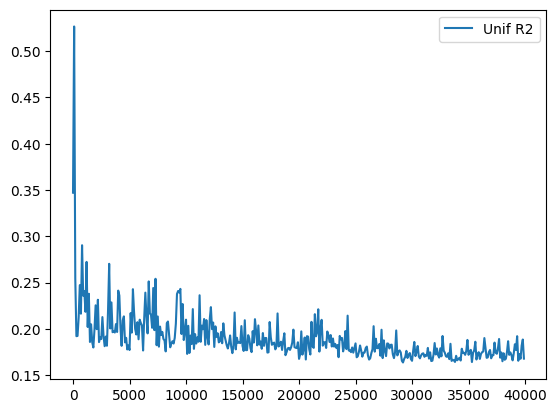

In [18]:
from matplotlib import scale

# plt.yscale("log")
# plt.ylim(10**-2, 10**0)
plt.plot(*zip(*scores_UR2), label = "Unif R2")
plt.legend()

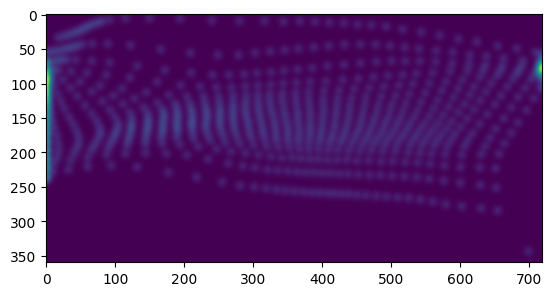

In [20]:
out = utils.filter_and_norm(model_unif_R2.grid_eval(), 5)

plt.imshow(out)

In [29]:
from copy import deepcopy

create_net = lambda: neural_net.MLP(channels_in = 2, channels_t = 256, channels_out = 2, layers = [128, 128, 128])

train_context = TrainingContext(training_steps = 100000, track_score=True, track_every=100)

ex_context_unif_R2 = ExecutionContext(target_dist=D, domain=domain.R2_Domain ,input_dist=dist.Uniform_Input_Distribution)
ex_context_param_R2 = ExecutionContext(target_dist=D, domain=domain.R2_Domain ,input_dist=dist.build_param_distribution(D.get_gaussian()))
ex_context_unif_wrap = ExecutionContext(target_dist=D, domain=domain.Wrapped_Square_Domain ,input_dist=dist.Uniform_Input_Distribution)
ex_context_param_wrap = ExecutionContext(target_dist=D, domain=domain.Wrapped_Square_Domain ,input_dist=dist.build_param_distribution(D.get_gaussian()))

model_unif_R2 = FlowM_Model(create_net(), ex_context_unif_R2, train_context)
model_param_R2 = FlowM_Model(create_net(), ex_context_param_R2, train_context)
model_unif_wrap = FlowM_Model(create_net(), ex_context_unif_wrap, train_context)
model_param_wrap = FlowM_Model (create_net(), ex_context_param_wrap, train_context)


scores_UR2 =model_unif_R2.train()
scores_PR2 =model_param_R2.train()
scores_UW =model_unif_wrap.train()
scores_PW =model_param_wrap.train()

100%|██████████| 100000/100000 [17:08<00:00, 97.23it/s, score=0.0493]


In [ ]:

model_unif_R2.animate_inference(30, 20, 1, "gifs/test_new_animate.gif", filter = True)

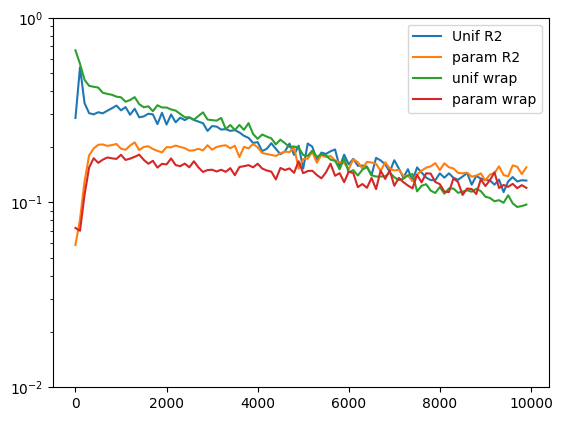

In [28]:
from matplotlib import scale

plt.yscale("log")
plt.ylim(10**-2, 10**0)
plt.plot(*zip(*scores_UR2), label = "Unif R2")
plt.plot(*zip(*scores_PR2), label = "param R2")
plt.plot(*zip(*scores_UW), label = "unif wrap")
plt.plot(*zip(*scores_PW), label = "param wrap")
plt.legend()

# Next Todos

- Rework model and context setup 
    - Have overarching model class, this holds everything needed to train, use and eval it (except input points for eval)
    - NeuralNet class, has no context, just the network, its definition and inference helpers
    - Have all the context within the overaching class:
        - input distribution
        - domain
        - training context
        - be able to specify loss function
        - be able to specify target dist sampling function
        - everything else needed
- Try to condition model on normal ?
- Figure out why parameterized input dist doesnt work for me
- In that Vein: Truly understand why Flow Matching works
    - Should'nt all points converge at mean of dist ?

In [16]:
def log_scores_zipped(scores):
    return np.log(np.array(list(zip(*scores))[1]))


print(log_scores_zipped(scores_UR2))

[-1.25030405 -0.61832099 -1.06504707 -1.19014049 -1.20493098 -1.17821946
 -1.19173893 -1.15908086 -1.128931   -1.09532707 -1.15430823 -1.1139429
 -1.20997228 -1.13422443 -1.24155647 -1.2298274  -1.19696313 -1.20490807
 -1.32624147 -1.18469326 -1.33152952 -1.2071229  -1.30349874 -1.2456745
 -1.27667078 -1.24289967 -1.2735834  -1.29491161 -1.31469267 -1.41069383
 -1.35070649 -1.3569948  -1.39401857 -1.38881113 -1.41040991 -1.40188203
 -1.43013279 -1.47188429 -1.49784164 -1.56093607 -1.55067775 -1.66202578
 -1.63472482 -1.56452307 -1.63405527 -1.70110723 -1.66526779 -1.56883202
 -1.7098838  -1.5949523  -1.87999011 -1.56801364 -1.60751357 -1.77438853
 -1.68073281 -1.69813867 -1.66447568 -1.6417997  -1.8582623  -1.70691871
 -1.8284525  -1.75868775 -1.84590691 -1.84278422 -1.85558688 -1.96385707
 -1.74660464 -1.77828629 -1.82677151 -1.9211423  -1.77637812 -1.87857199
 -1.99368549 -1.88794978 -2.0351456  -1.86575001 -1.9301153  -1.99181239
 -2.02381393 -2.02494206 -1.94012071 -1.99326166 -1.9

In [ ]:


plt.plot(*zip(*scores_UR2), label = "Unif R2")
plt.plot(*zip(*scores_PR2), label = "param R2")
plt.plot(*zip(*scores_UW), label = "unif wrap")
plt.plot(*zip(*scores_PW), label = "param wrap")
plt.legend()

In [ ]:
net = neural_net.MLP(channels_in = 2, channels_t = 256, channels_out = 2, layers = [256, 256, 256, 128])
large_train_context = TrainingContext(training_steps=300_000, track_score=True, track_every=2000)
ex_context = ExecutionContext(target_dist=D, domain=domain.Wrapped_Square_Domain ,input_dist=dist.Uniform_Input_Distribution)

test_large = FlowM_Model(net, ex_context, large_train_context)

scores_large = test_large.train()

100%|██████████| 300000/300000 [1:01:46<00:00, 80.93it/s, score=0.0299]


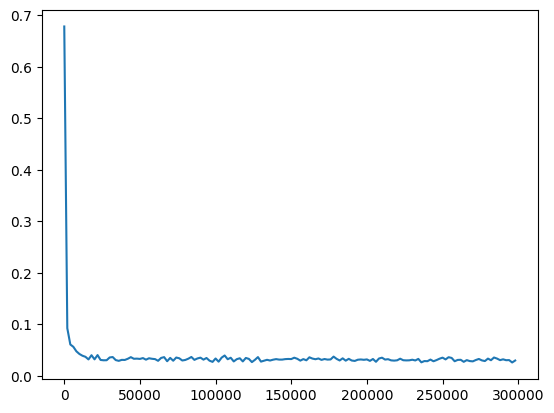

In [9]:
plt.plot(*zip(*scores_large), label = "large")

In [ ]:
from math import pi, sin, cos

def point_to_unit_sphere(point: np.ndarray):
    phi = point[0] * 2 * pi             # azimuth angle
    psi = - (point[1] * 2 - 1) * pi  / 2  # polar angle
    return (cos(phi) * cos(psi), sin(phi) * cos(psi), sin(psi))

def points_to_unit_sphere(points: np.ndarray):
    return [point_to_unit_sphere(p) for p in points]

def normalize(v):
    norm = np.linalg.norm(v)
    if norm == 0: 
       return v
    return v / norm

points = np.array([
    [1, 0.5],    # target: (1, 0, 0)
    [0.5, 0.5],  # target: (-1, 0, 0)
    [0.25, 0.5], # target: (0, 1, 0)
    [0.75, 0.5], # target: (0, -1, 0)
    [1, 1],      # target: (0, 0, 1)
    [1, 0]       # target: (0, 0, -1)
])

transformed = points_to_unit_sphere(points)
for p in transformed:
    pass
    # print(p)

dims_tuple = D.get_dims()
dims = [dims_tuple[0], dims_tuple[1]]
rev_dims = [dims[1], dims[0]]
arr = np.zeros(rev_dims)
lambert_cos = np.zeros(rev_dims)


normal = normalize(np.random.rand(3) * 2 - 1)

for y in range(len(arr)):
    for x in range(len(arr[y])):
        uvs = np.array([x, y]) / 
        dir = point_to_unit_sphere(uvs)
        dot_prd = np.dot(dir, normal)
        arr[y][x] = D.dist[y][x] / 255 * dot_prd
        lambert_cos[y][x] = dot_prd

cv2.imshow("fade", arr)
cv2.imshow("lambert", lambert_cos)
cv2.waitKey()
cv2.destroyAllWindows()
